# Métricas FID/KID para o DDPM UTKFace

Este notebook compara imagens reais do subconjunto `utkface_female_20_40_128` com imagens geradas por checkpoints do modelo DDPM.

Métricas calculadas:

- **FID**: Frechet Inception Distance. Menor é melhor.
- **KID**: Kernel Inception Distance. Menor é melhor; costuma ser mais estável que FID quando há poucas amostras.

Observação: FID com poucas imagens é ruidoso. Use `NUM_EVAL_IMAGES >= 1000` para uma avaliação mais confiável, se houver tempo de geração.

In [10]:
# Se necessário, instale as dependências antes de rodar o restante do notebook:
# !pip install torchmetrics torch-fidelity pandas matplotlib

import math
import os
import random
from pathlib import Path

import pandas as pd
import torch
import yaml
from PIL import Image
from torchmetrics.image.fid import FrechetInceptionDistance
from torchmetrics.image.kid import KernelInceptionDistance
from torchvision import transforms
from tqdm.auto import tqdm

from ddpm import NoiseScheduler
from model import SimpleUNet
from sampling import sample_ddpm

In [11]:
CONFIG_PATH = Path("config.yaml")
with CONFIG_PATH.open("r", encoding="utf-8") as file:
    config = yaml.safe_load(file)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42

DATA_DIR = Path(config["data_dir"])
CHECKPOINT_DIR = Path(config["output_dir"])
IMAGE_SIZE = int(config["image_size"])
TIMESTEPS = int(config["timesteps"])
BASE_CHANNELS = int(config["base_channels"])

# Comece com um valor pequeno para validar o fluxo. Para FID mais confiável, use 1000 ou mais.
NUM_EVAL_IMAGES = 256
REAL_BATCH_SIZE = 64
GEN_BATCH_SIZE = 16

RESULTS_CSV = Path("metrics_utkface_fid_kid.csv")

random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Device: {DEVICE}")
print(f"Dataset: {DATA_DIR}")
print(f"Checkpoints: {CHECKPOINT_DIR}")

Device: cuda
Dataset: data/utkface_female_20_40_128
Checkpoints: checkpoints/utkface_female_20_40_128


## Checkpoints avaliados

Por padrão, o notebook avalia todos os checkpoints `diffusion_epoch*.pt` e também `diffusion_final.pt`, se existir. Edite `checkpoint_paths` se quiser avaliar apenas alguns arquivos.

In [12]:
def checkpoint_sort_key(path):
    stem = path.stem
    if stem == "diffusion_final":
        return (10**9, stem)
    if stem.startswith("diffusion_epoch"):
        try:
            return (int(stem.replace("diffusion_epoch", "")), stem)
        except ValueError:
            pass
    return (10**8, stem)

def is_compatible_checkpoint(path):
    checkpoint = torch.load(path, map_location="cpu")
    state_key = "ema_model_state_dict" if "ema_model_state_dict" in checkpoint else "model_state_dict"
    state = checkpoint[state_key]
    return "down1.0.time_mlp.1.weight" in state

all_checkpoint_paths = sorted(CHECKPOINT_DIR.glob("diffusion_epoch*.pt"), key=checkpoint_sort_key)
final_checkpoint = CHECKPOINT_DIR / "diffusion_final.pt"
if final_checkpoint.exists():
    all_checkpoint_paths.append(final_checkpoint)

checkpoint_paths = []
skipped_checkpoint_paths = []
for path in all_checkpoint_paths:
    if is_compatible_checkpoint(path):
        checkpoint_paths.append(path)
    else:
        skipped_checkpoint_paths.append(path)

print("Checkpoints compatíveis:")
for path in checkpoint_paths:
    print(f"- {path.name}")

if skipped_checkpoint_paths:
    print("\nCheckpoints ignorados por incompatibilidade com a arquitetura atual:")
    for path in skipped_checkpoint_paths:
        print(f"- {path.name}")


/tmp/ipykernel_49376/3705071310.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(path, map_location="cpu")


Checkpoints compatíveis:
- diffusion_epoch25.pt
- diffusion_epoch50.pt
- diffusion_epoch75.pt
- diffusion_epoch100.pt
- diffusion_epoch125.pt
- diffusion_epoch150.pt
- diffusion_epoch175.pt
- diffusion_epoch200.pt
- diffusion_final.pt

Checkpoints ignorados por incompatibilidade com a arquitetura atual:
- diffusion_epoch10.pt
- diffusion_epoch20.pt
- diffusion_epoch30.pt
- diffusion_epoch40.pt


In [13]:
IMG_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}
image_paths = sorted(p for p in DATA_DIR.rglob("*") if p.suffix.lower() in IMG_EXTENSIONS)
if len(image_paths) == 0:
    raise ValueError(f"Nenhuma imagem encontrada em {DATA_DIR}")

num_real_images = min(NUM_EVAL_IMAGES, len(image_paths))
real_paths = random.sample(image_paths, num_real_images)

real_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
])

print(f"Imagens reais disponíveis: {len(image_paths)}")
print(f"Imagens reais usadas por avaliação: {num_real_images}")

Imagens reais disponíveis: 4659
Imagens reais usadas por avaliação: 256


In [14]:
def to_uint8(images):
    """Converte imagens em [0, 1] float para uint8 [0, 255]."""
    return (images.clamp(0, 1) * 255).round().to(torch.uint8)


def generated_to_uint8(images):
    """Converte imagens geradas em [-1, 1] para uint8 [0, 255]."""
    return to_uint8((images + 1) / 2)


def iter_real_batches(paths, batch_size):
    for start in range(0, len(paths), batch_size):
        batch_paths = paths[start:start + batch_size]
        images = []
        for path in batch_paths:
            with Image.open(path) as img:
                images.append(real_transform(img.convert("RGB")))
        yield to_uint8(torch.stack(images, dim=0))


def load_model_from_checkpoint(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    train_config = checkpoint.get("config", config)

    model = SimpleUNet(
        in_channels=3,
        base_ch=int(train_config["base_channels"]),
    ).to(DEVICE)

    state_key = "ema_model_state_dict" if "ema_model_state_dict" in checkpoint else "model_state_dict"
    model.load_state_dict(checkpoint[state_key])
    model.eval()

    scheduler = NoiseScheduler(
        num_timesteps=int(train_config["timesteps"]),
        device=DEVICE,
    )

    return model, scheduler, train_config, state_key


def infer_epoch(checkpoint_path):
    stem = checkpoint_path.stem
    if stem == "diffusion_final":
        return "final"
    if stem.startswith("diffusion_epoch"):
        return stem.replace("diffusion_epoch", "")
    return stem

## Cálculo de FID/KID

A célula abaixo gera imagens novas para cada checkpoint. Isso pode demorar bastante, pois a amostragem DDPM usa `TIMESTEPS=1000`.

In [15]:
def compute_metrics_for_checkpoint(checkpoint_path):
    model, scheduler, train_config, state_key = load_model_from_checkpoint(checkpoint_path)
    image_size = int(train_config["image_size"])

    fid = FrechetInceptionDistance(feature=2048).to(DEVICE)
    kid = KernelInceptionDistance(feature=2048, subset_size=min(100, num_real_images)).to(DEVICE)

    for real_batch in tqdm(iter_real_batches(real_paths, REAL_BATCH_SIZE), total=math.ceil(num_real_images / REAL_BATCH_SIZE), desc="Reais"):
        real_batch = real_batch.to(DEVICE)
        fid.update(real_batch, real=True)
        kid.update(real_batch, real=True)

    generated_count = 0
    gen_pbar = tqdm(total=num_real_images, desc="Geradas")
    while generated_count < num_real_images:
        batch_size = min(GEN_BATCH_SIZE, num_real_images - generated_count)
        generated, _ = sample_ddpm(
            model=model,
            scheduler=scheduler,
            num_images=batch_size,
            image_size=image_size,
            device=DEVICE,
            save_intermediates=None,
        )
        generated_uint8 = generated_to_uint8(generated).to(DEVICE)
        fid.update(generated_uint8, real=False)
        kid.update(generated_uint8, real=False)
        generated_count += batch_size
        gen_pbar.update(batch_size)
    gen_pbar.close()

    fid_value = float(fid.compute().detach().cpu())
    kid_mean, kid_std = kid.compute()

    del model, scheduler, fid, kid
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "checkpoint": checkpoint_path.name,
        "epoch": infer_epoch(checkpoint_path),
        "weights": state_key,
        "num_images": num_real_images,
        "fid": fid_value,
        "kid_mean": float(kid_mean.detach().cpu()),
        "kid_std": float(kid_std.detach().cpu()),
    }

In [16]:
results = []

for checkpoint_path in checkpoint_paths:
    print(f"\nAvaliando {checkpoint_path.name}")
    result = compute_metrics_for_checkpoint(checkpoint_path)
    results.append(result)

    df_partial = pd.DataFrame(results)
    df_partial.to_csv(RESULTS_CSV, index=False)
    display(df_partial)

df = pd.DataFrame(results)
df


Avaliando diffusion_epoch25.pt


/tmp/ipykernel_49376/1840477859.py:22: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
Downloading: "https://gith

,checkpoint,epoch,weights,num_images,fid,kid_mean,kid_std
0,diffusion_epoch25.pt,25,ema_model_state_dict,256,109.550415,0.047523,0.004993



Avaliando diffusion_epoch50.pt


/tmp/ipykernel_49376/1840477859.py:22: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
/mnt/dados_sda/lorran/LNCC

...

,checkpoint,epoch,weights,num_images,fid,kid_mean,kid_std
0,diffusion_epoch25.pt,25,ema_model_state_dict,256,109.550415,0.047523,0.004993
1,diffusion_epoch50.pt,50,ema_model_state_dict,256,143.004456,0.070117,0.007390
2,diffusion_epoch75.pt,75,ema_model_state_dict,256,160.157013,0.087633,0.008236
3,diffusion_epoch100.pt,100,ema_model_state_dict,256,182.153137,0.111945,0.009147
4,diffusion_epoch125.pt,125,ema_model_state_dict,256,173.445145,0.099665,0.008376
5,diffusion_epoch150.pt,150,ema_model_state_dict,256,184.371277,0.109857,0.009681
6,diffusion_epoch175.pt,175,ema_model_state_dict,256,165.580887,0.090070,0.010288
7,diffusion_epoch200.pt,200,ema_model_state_dict,256,151.658035,0.073759,0.007603



Avaliando diffusion_final.pt


/tmp/ipykernel_49376/1840477859.py:22: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
/mnt/dados_sda/lorran/LNCC

,checkpoint,epoch,weights,num_images,fid,kid_mean,kid_std
0,diffusion_epoch25.pt,25,ema_model_state_dict,256,109.550415,0.047523,0.004993
1,diffusion_epoch50.pt,50,ema_model_state_dict,256,143.004456,0.070117,0.007390
2,diffusion_epoch75.pt,75,ema_model_state_dict,256,160.157013,0.087633,0.008236
3,diffusion_epoch100.pt,100,ema_model_state_dict,256,182.153137,0.111945,0.009147
4,diffusion_epoch125.pt,125,ema_model_state_dict,256,173.445145,0.099665,0.008376
5,diffusion_epoch150.pt,150,ema_model_state_dict,256,184.371277,0.109857,0.009681
6,diffusion_epoch175.pt,175,ema_model_state_dict,256,165.580887,0.090070,0.010288
7,diffusion_epoch200.pt,200,ema_model_state_dict,256,151.658035,0.073759,0.007603
8,diffusion_final.pt,final,ema_model_state_dict,256,146.642548,0.066245,0.008060


,checkpoint,epoch,weights,num_images,fid,kid_mean,kid_std
0,diffusion_epoch25.pt,25,ema_model_state_dict,256,109.550415,0.047523,0.004993
1,diffusion_epoch50.pt,50,ema_model_state_dict,256,143.004456,0.070117,0.007390
2,diffusion_epoch75.pt,75,ema_model_state_dict,256,160.157013,0.087633,0.008236
3,diffusion_epoch100.pt,100,ema_model_state_dict,256,182.153137,0.111945,0.009147
4,diffusion_epoch125.pt,125,ema_model_state_dict,256,173.445145,0.099665,0.008376
5,diffusion_epoch150.pt,150,ema_model_state_dict,256,184.371277,0.109857,0.009681
6,diffusion_epoch175.pt,175,ema_model_state_dict,256,165.580887,0.090070,0.010288
7,diffusion_epoch200.pt,200,ema_model_state_dict,256,151.658035,0.073759,0.007603
8,diffusion_final.pt,final,ema_model_state_dict,256,146.642548,0.066245,0.008060


In [17]:
df = pd.read_csv(RESULTS_CSV) if RESULTS_CSV.exists() else pd.DataFrame(results)
df


,checkpoint,epoch,weights,num_images,fid,kid_mean,kid_std
0,diffusion_epoch25.pt,25,ema_model_state_dict,256,109.550415,0.047523,0.004993
1,diffusion_epoch50.pt,50,ema_model_state_dict,256,143.004456,0.070117,0.007390
2,diffusion_epoch75.pt,75,ema_model_state_dict,256,160.157013,0.087633,0.008236
3,diffusion_epoch100.pt,100,ema_model_state_dict,256,182.153137,0.111945,0.009147
4,diffusion_epoch125.pt,125,ema_model_state_dict,256,173.445145,0.099665,0.008376
5,diffusion_epoch150.pt,150,ema_model_state_dict,256,184.371277,0.109857,0.009681
6,diffusion_epoch175.pt,175,ema_model_state_dict,256,165.580887,0.090070,0.010288
7,diffusion_epoch200.pt,200,ema_model_state_dict,256,151.658035,0.073759,0.007603
8,diffusion_final.pt,final,ema_model_state_dict,256,146.642548,0.066245,0.008060


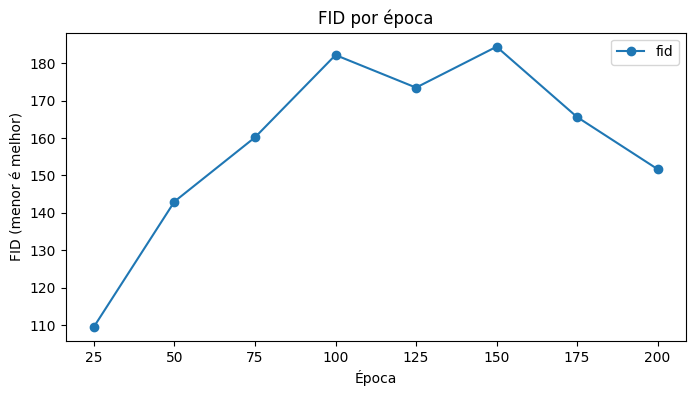

In [18]:
plot_df = df.copy()
plot_df["epoch_numeric"] = pd.to_numeric(plot_df["epoch"], errors="coerce")
plot_df = plot_df.dropna(subset=["epoch_numeric"]).sort_values("epoch_numeric")

if len(plot_df) > 0:
    ax = plot_df.plot(x="epoch_numeric", y="fid", marker="o", figsize=(8, 4), title="FID por época")
    ax.set_xlabel("Época")
    ax.set_ylabel("FID (menor é melhor)")
else:
    print("Não há checkpoints de época numérica para plotar.")

## Dicas de uso

- Para um teste rápido, mantenha `NUM_EVAL_IMAGES = 256`.
- Para relatório ou apresentação, prefira `NUM_EVAL_IMAGES = 1000` ou mais.
- Para avaliar apenas alguns checkpoints, edite a lista `checkpoint_paths`.
- O arquivo `metrics_utkface_fid_kid.csv` é atualizado após cada checkpoint, então resultados parciais ficam salvos mesmo se a execução for interrompida.